In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [41]:
insurance = pd.read_csv("insurance.csv")
display(insurance.shape)
display(insurance.size)
display(insurance.head())
display(insurance.info())
display(insurance.describe())

(1338, 7)

9366

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


None

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [42]:
display(insurance.isna().sum())
""" As we can see there is no null value in any col"""

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

' As we can see there is no null value in any col'

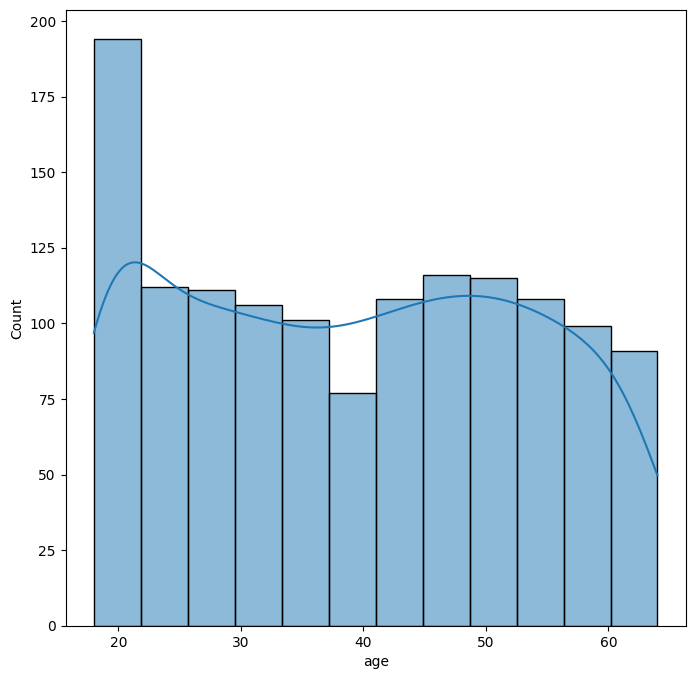

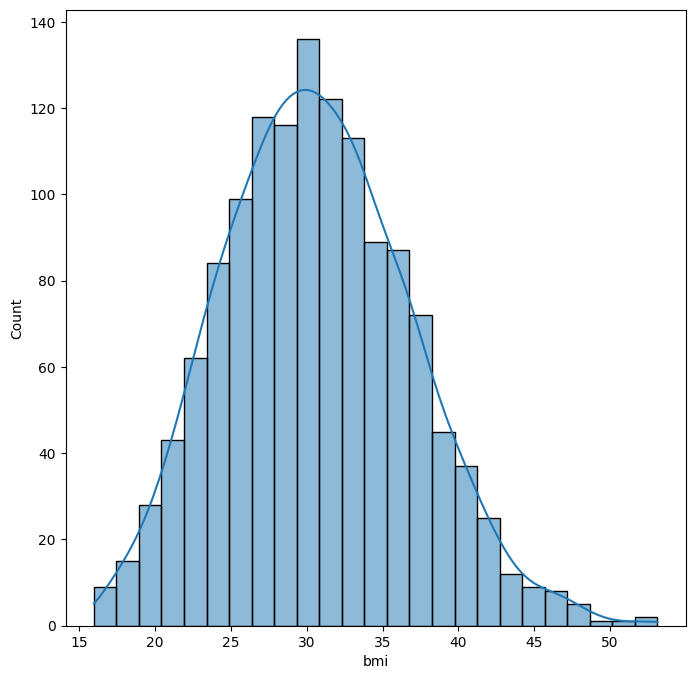

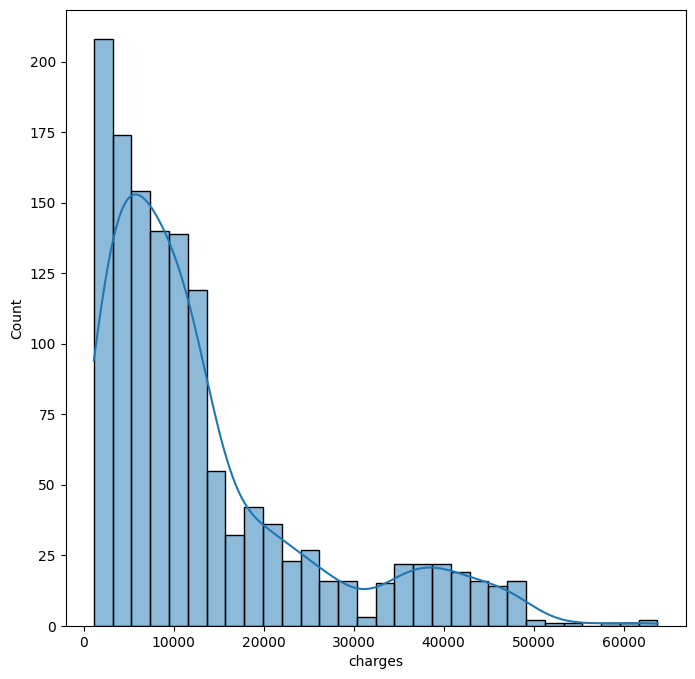

In [43]:
numeric = ["age","bmi","charges"]
for x in numeric:                               # We did not take children col becuase that is discrete value not contniues 
    plt.figure(figsize=(8,8))
    sns.histplot(x=insurance[x],kde=True)

Here charge col only right skewed 

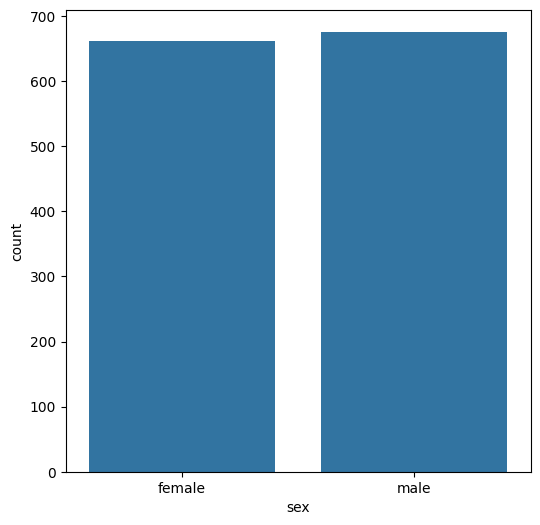

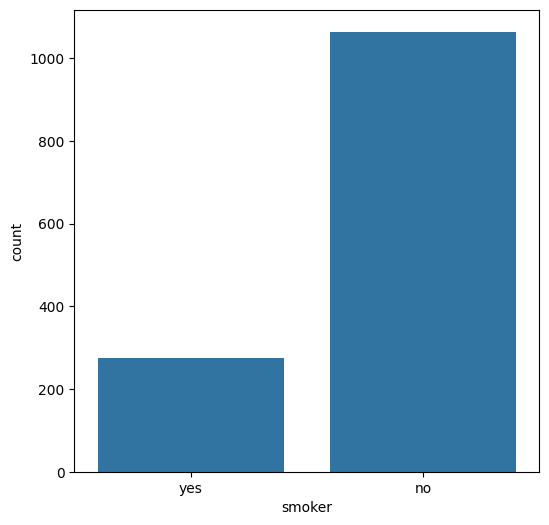

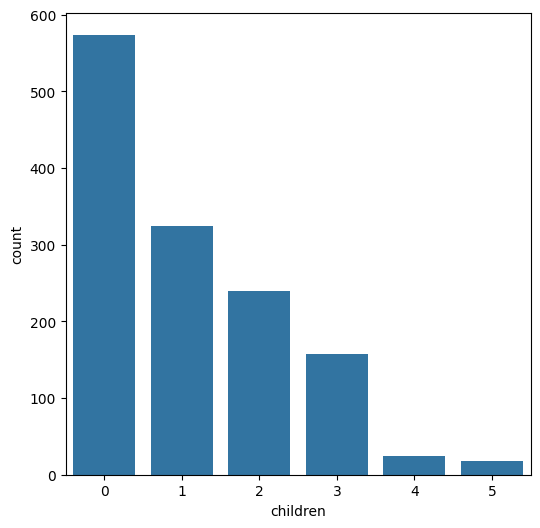

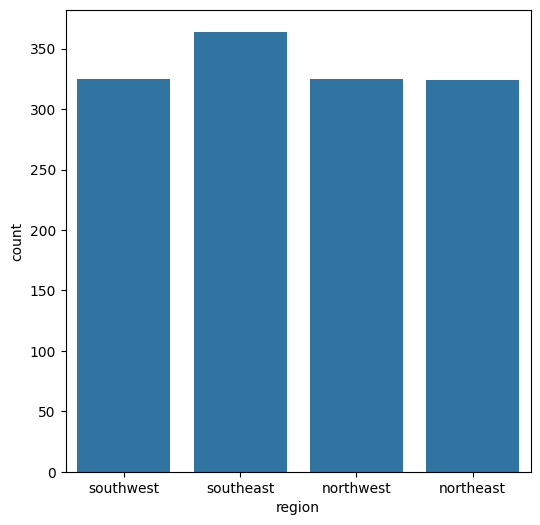

In [44]:
non_numeric = ['sex','smoker','children','region']
for x  in  non_numeric: 
    plt.figure(figsize=(6,6))
    sns.countplot(x=insurance[x])

<Axes: xlabel='smoker', ylabel='count'>

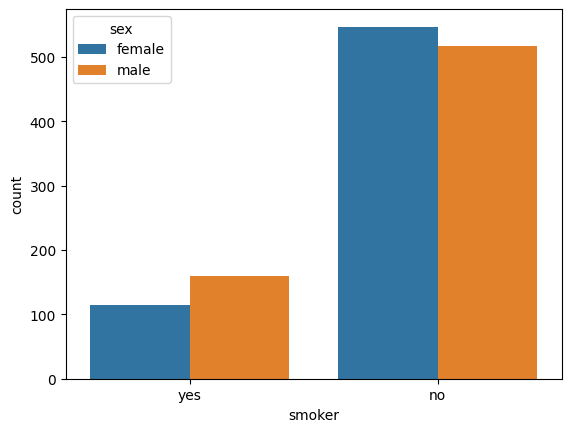

In [45]:
sns.countplot(data =insurance,x='smoker',hue='sex')

<Axes: xlabel='smoker', ylabel='count'>

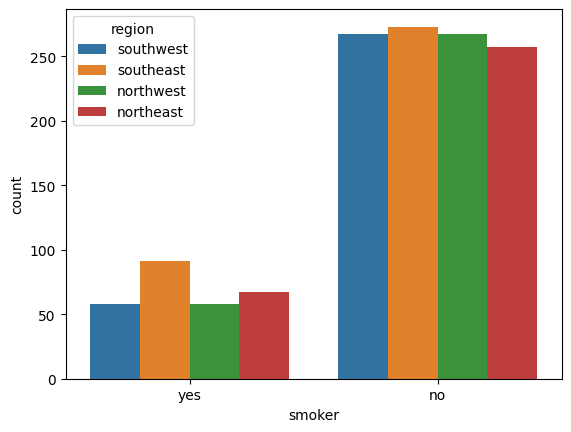

In [46]:
sns.countplot(data =insurance,x='smoker',hue='region')

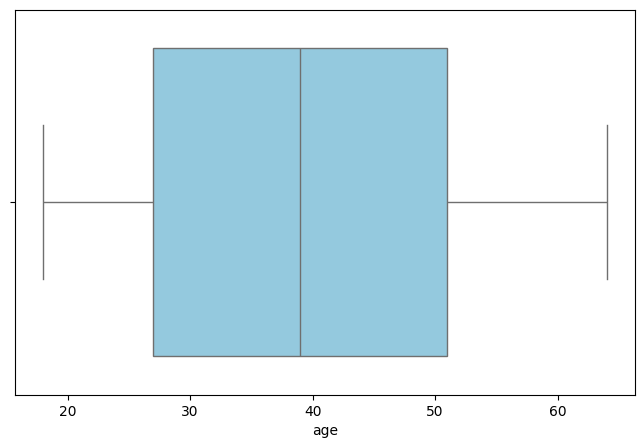

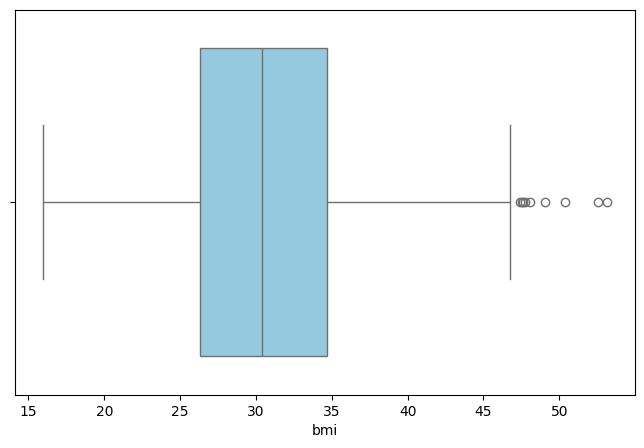

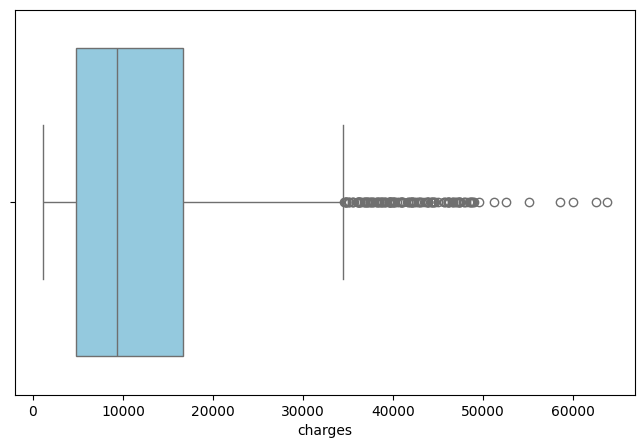

In [47]:
for  i in numeric:
    plt.figure(figsize=(8,5))
    sns.boxplot(data=insurance, x=i, color="skyblue")


In [48]:
insurance['bmi'].max()

53.13

In [49]:
x = insurance[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = insurance[['charges']]

In [50]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [51]:
X_train.shape

(1070, 6)

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
colct = ColumnTransformer(transformers=[('encoder',OneHotEncoder(sparse_output=False,drop='first'),['sex','smoker','region'])],remainder='passthrough')
transformed_data = colct.fit_transform(X_train)
transformed_test = colct.transform(X_test)
column_names = colct.get_feature_names_out()
new_df = pd.DataFrame(transformed_data, columns=column_names)
new_test = pd.DataFrame(transformed_test,columns=column_names)

In [85]:
new_df.head()

,encoder__sex_male,encoder__smoker_yes,encoder__region_northwest,encoder__region_southeast,encoder__region_southwest,remainder__age,remainder__bmi,remainder__children
0,0.0,0.0,1.0,0.0,0.0,46.0,19.95,2.0
1,0.0,0.0,0.0,0.0,0.0,47.0,24.32,0.0
2,0.0,0.0,0.0,1.0,0.0,52.0,24.86,0.0
3,0.0,0.0,0.0,1.0,0.0,39.0,34.32,5.0
4,0.0,0.0,1.0,0.0,0.0,54.0,21.47,3.0


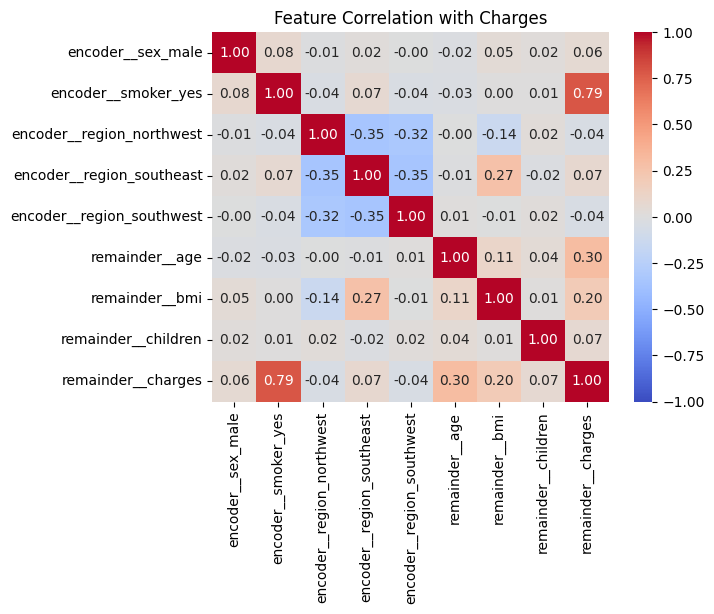

In [70]:
target_corr = new_df.corr()
sns.heatmap(target_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Feature Correlation with Charges")
plt.show()

In [78]:
from sklearn.linear_model import LinearRegression
x = new_df[["remainder__age","remainder__bmi","encoder__smoker_yes"]]
y = new_df["remainder__charges"]
Linear = LinearRegression()
Linear.fit(x,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [87]:
x = new_test[["remainder__age","remainder__bmi","encoder__smoker_yes"]]
y = Linear.predict(x)
y

array([ 8124.64266337,  7351.78555791, 37431.40137528,  8568.08078063,
       27376.13144919, 10987.97348551,   518.25162972, 17162.93564364,
        1168.51498471, 10296.82482143, 27805.08805746,  8833.41364137,
        5396.22860993, 37748.78955639, 40921.11479819, 36908.21944503,
       14810.21052957, 36162.97848822,  9311.70866177, 31980.90405269,
        2522.35853798, 10000.96504144,  3062.071952  ,  6874.90975082,
       10372.48168728, 12881.79665914, 15219.81022987,  5138.45188441,
        9103.46421074,  2718.64452591,  8157.69262849, 13384.60319524,
        5023.2565788 ,  2545.76622111,  4749.85833973, 12844.50205651,
        2290.70640383,  9129.90418283, 33428.02678574, 32846.61644122,
        2481.36471292,  4147.19880283, 14407.45085664, 11850.25285795,
        8421.72779431, 12508.3877289 ,  4623.21381411,  2651.40459111,
       34911.86253435,  8754.33676184, 16385.59086391,  2470.23087364,
       12067.78803825,  1423.34476764, 13965.46812468, 11659.71606723,
      